In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [2]:
#change the initialization as ordering of the Qvalues


In [22]:
# Parameters
t = 1
s = 0
r = 0.9
p = 0.2
epsilon = 0.1
d = 0.1
alpha = 0.3
bound = 1 / (1 - d)

In [31]:

algo = Algorithm(
        e=epsilon, lambda_val=0, alpha=alpha, delta=d,
        init_mode='fixed', tolerance=1e-10000, 
        M=int(50), strategy1='AC', strategy2='AC', verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()  
exp = np.random.randint(0, 50)
q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]  

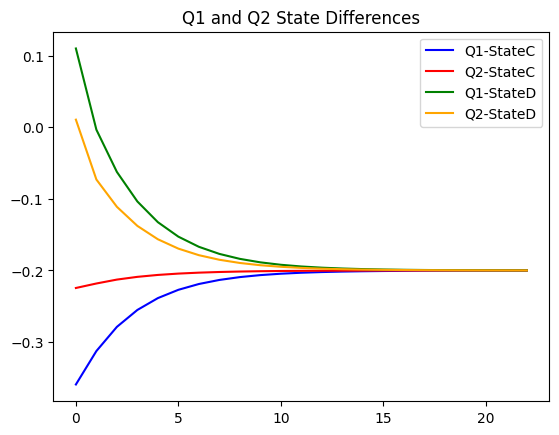

In [32]:
internal_debug = True
if internal_debug:
    q1['StateC'] = q1['Q1'] - q1['Q3']
    q1['StateD'] = q1['Q2'] - q1['Q4']
    q2['StateC'] = q2['Q1'] - q2['Q3']
    q2['StateD'] = q2['Q2'] - q2['Q4']
    x = q1['StateC'].values
    y = q2['StateC'].values
    z = q1['StateD'].values
    w = q2['StateD'].values
    pd.Series(x).plot(title='Q1-StateC', color='blue')
    pd.Series(y).plot(title='Q2-StateC', color='red')
    pd.Series(z).plot(title='Q1-StateD', color='green')
    pd.Series(w).plot(title='Q2-StateD', color='orange')
    plt.title('Q1 and Q2 State Differences')
    plt.legend(['Q1-StateC', 'Q2-StateC', 'Q1-StateD', 'Q2-StateD'])


In [33]:
#q1.join(q2, rsuffix='_q2', lsuffix='_q1')


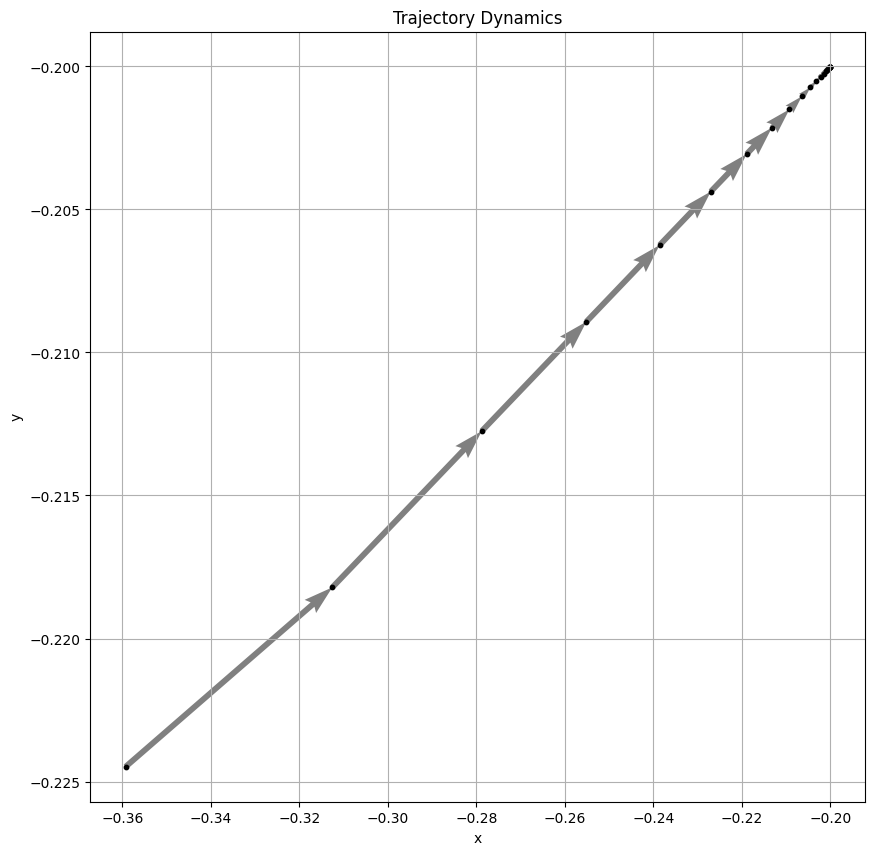

In [34]:
trajectory_dynamics_plot(x, y)

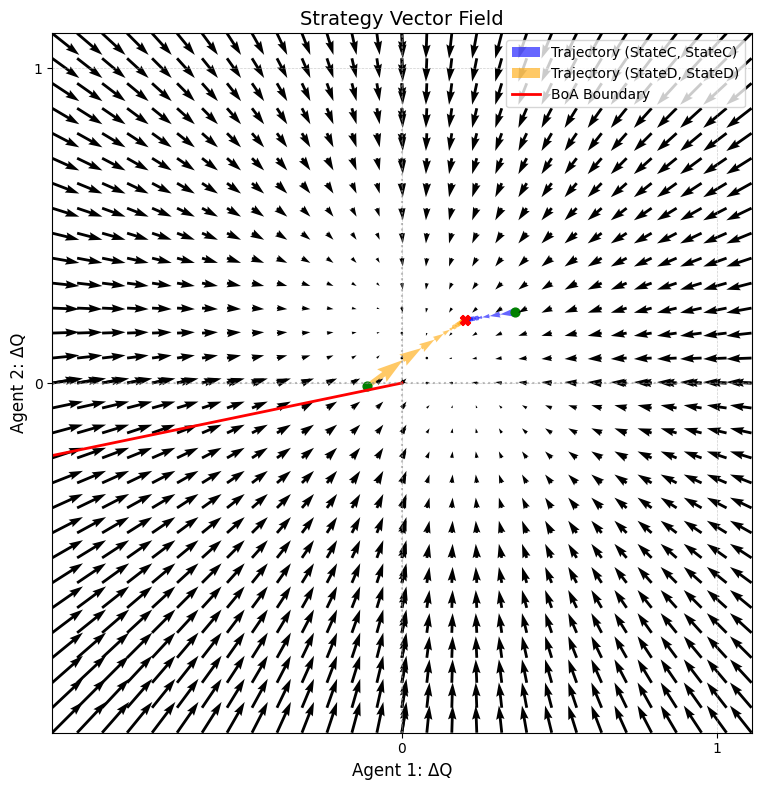

/Users/giuseppe.martucci/Desktop/Async_Dec_Q/MultiAgent/basin.py:374: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


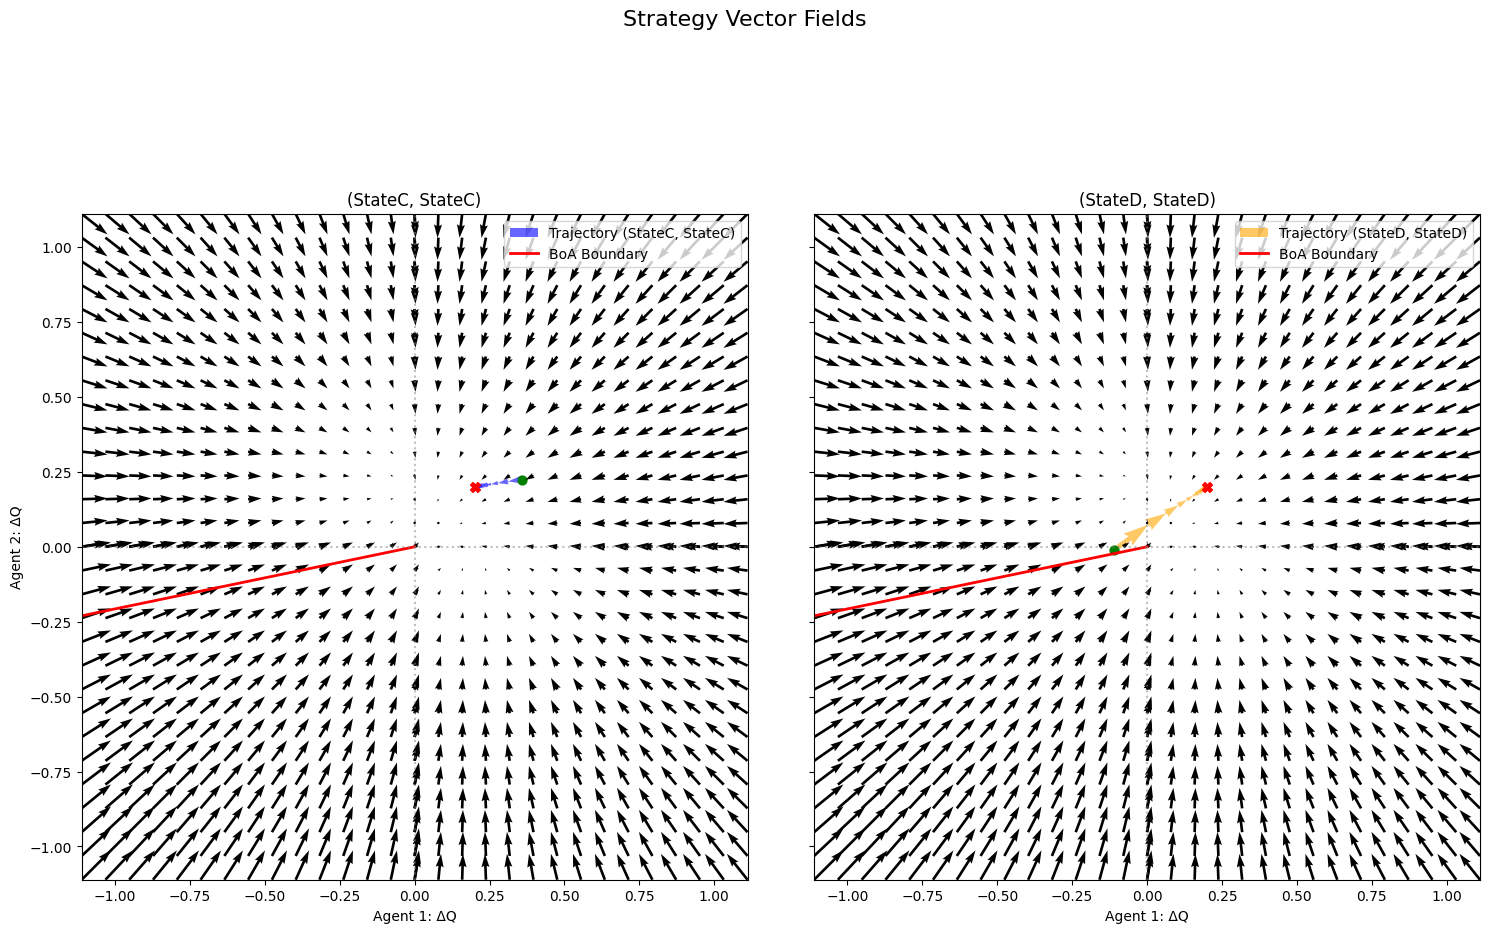

In [35]:
plotter = VectorFieldPlotter(q1 = q1, q2 = q2,
    t=t, r=r, p=p, s=s, alpha=alpha,
    bound=bound,
    epsilon=epsilon, delta=d,
    q_func_gt=QvaluesADvsAD,
    q_func_ad=QvaluesGTvsGT,  method = "quiver",cmap=cm.viridis,
    show_trajectory=True,
    show_basin=True, 

)
plotter.plot()
plotter.plot_subplots()

In [28]:
#NEW VECTOR FIELD PLOTTER

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

class VectorFieldPlot:
    """
    Plots vector fields from two Q-functions (func1 for x, func2 for y),
    with trajectories from Q-learning runs and Basin of Attraction (BoA) boundary.
    """

    def __init__(self, q1=None, q2=None,
                 t=1, r=3, p=0, s=5, epsilon=0.01, d=0.9,
                 func1=None, func2=None,
                 alpha=0.1, bound=1.0,
                 method="quiver", cmap=cm.viridis,
                 show_trajectory=True, show_basin=True):

        self.q1 = q1
        self.q2 = q2
        self.t, self.r, self.p, self.s = t, r, p, s
        self.epsilon, self.d = epsilon, d
        self.alpha, self.bound = alpha, bound
        self.show_trajectory, self.show_basin = show_trajectory, show_basin
        self.method, self.cmap = method, cmap
        self.eps = 1e-8

        self.func1 = func1  # x-component Q-function
        self.func2 = func2  # y-component Q-function

        if self.show_trajectory:
            if self.q1 is None or self.q2 is None:
                raise ValueError("q1 and q2 must be provided if show_trajectory is True.")
            self.prepare_states()
        else:
            self.xC = self.yC = self.uC = self.vC = None
            self.xD = self.yD = self.uD = self.vD = None

        self.compute_deltas()

    def prepare_states(self):
        """Computes StateC and StateD trajectories for both agents."""
        self.q1['StateC'] = self.q1['Q3'] - self.q1['Q1']
        self.q1['StateD'] = self.q1['Q4'] - self.q1['Q2']
        self.q2['StateC'] = self.q2['Q3'] - self.q2['Q1']
        self.q2['StateD'] = self.q2['Q4'] - self.q2['Q2']

        self.xC, self.yC = self.q1['StateC'].values, self.q2['StateC'].values
        self.uC, self.vC = self.xC[1:] - self.xC[:-1], self.yC[1:] - self.yC[:-1]

        self.xD, self.yD = self.q1['StateD'].values, self.q2['StateD'].values
        self.uD, self.vD = self.xD[1:] - self.xD[:-1], self.yD[1:] - self.yD[:-1]

    def compute_deltas(self):
        """Compute ΔQ and BoA boundary using func1 (x) and func2 (y)."""
        Q1 = self.func1(self.t, self.r, self.p, self.s, self.epsilon, self.d)
        Q2 = self.func2(self.t, self.r, self.p, self.s, self.epsilon, self.d)

        # use row [0] for dx, row [0] for dy (consistent with Mathematica)
        self.dx = Q1[0][0] - Q1[0][1]
        self.dy = Q2[0][0] - Q2[0][1]

        inv_scale_dx = 1 / ((1 - self.d) * abs(self.dx) + self.eps)
        inv_scale_dy = 1 / ((1 - self.d) * abs(self.dy) + self.eps)
        self.a = min(inv_scale_dx, inv_scale_dy)
        self.end_x, self.end_y = -self.a * self.dx, -self.a * self.dy

        self.Q1, self.Q2 = Q1, Q2  # store for vector fields

    def field(self, X, Y, idx):
        """Vector field using row idx (0 or 1)."""
        U = self.alpha * (self.Q1[idx][0] - self.Q1[idx][1] - X)
        V = self.alpha * (self.Q2[idx][0] - self.Q2[idx][1] - Y)
        return U, V

    def add_vector_field(self, ax, field_func, x_range, y_range, density=15):
        x_vals = np.linspace(x_range[0], x_range[1], density)
        y_vals = np.linspace(y_range[0], y_range[1], density)
        X, Y = np.meshgrid(x_vals, y_vals)
        U, V = field_func(X, Y)
        ax.quiver(X, Y, U, V, angles='xy', scale_units='xy', scale=3)

    def plot(self):
        """Generates the vector field plot with trajectories and BoA boundary."""
        fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

        for i, ax in enumerate(axes):
            # vector fields from row i (0 and 1)
            self.add_vector_field(ax, lambda X, Y, idx=i: self.field(X, Y, idx),
                                  (-self.bound, self.bound), (-self.bound, self.bound))

            if self.show_trajectory:
                if i == 0:
                    ax.quiver(self.xC[:-1], self.yC[:-1], self.uC, self.vC,
                              angles='xy', scale_units='xy', scale=1,
                              color='blue', alpha=0.6, label='Trajectory (StateC, StateC)')
                else:
                    ax.quiver(self.xD[:-1], self.yD[:-1], self.uD, self.vD,
                              angles='xy', scale_units='xy', scale=1,
                              color='orange', alpha=0.6, label='Trajectory (StateD, StateD)')

            if self.show_basin:
                ax.plot([0, self.end_x], [0, self.end_y],
                        color='red', linewidth=2, label='BoA Boundary')

            ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
            ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
            ax.set_xlim(-self.bound, self.bound)
            ax.set_ylim(-self.bound, self.bound)
            ax.set_aspect('equal')
            ax.set_xlabel("Agent 1: ΔQ")
            ax.set_ylabel("Agent 2: ΔQ")
            ax.legend()
            ax.set_title(f"Vector Field {i+1}")

        plt.tight_layout()
        plt.show()


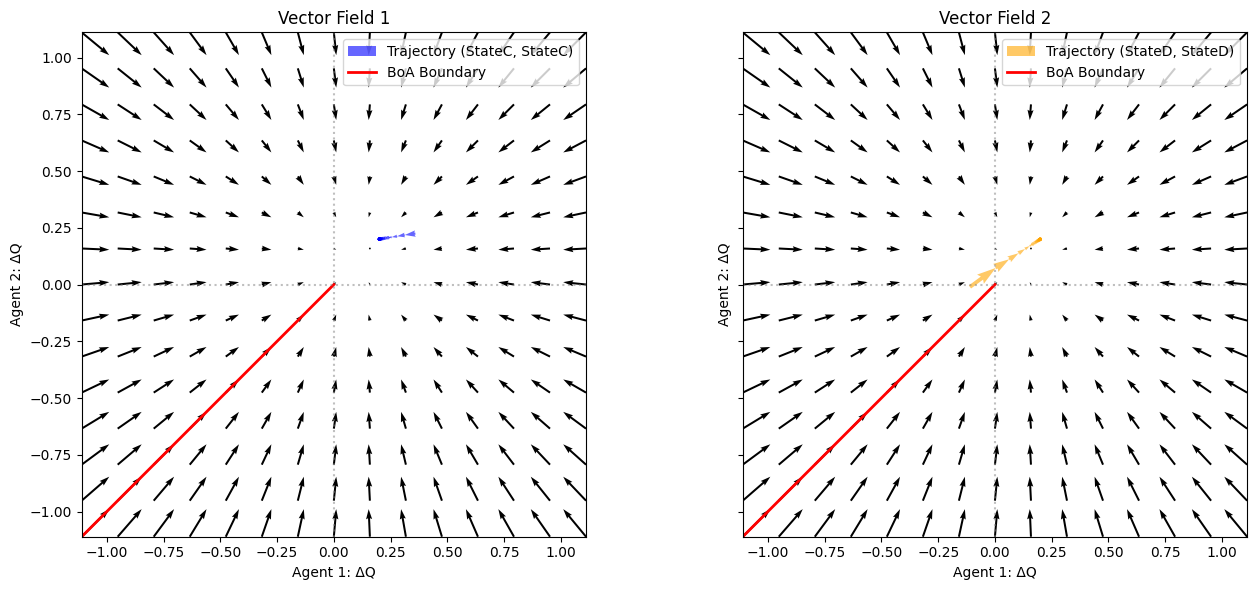

In [36]:
plotter = VectorFieldPlot(
    q1=q1, q2=q2,
    t=t, r=r, p=p, s=s, epsilon=epsilon, d=d,
    func1=QvaluesADvsAC,   # function for x-component
    func2=QvaluesADvsAC,   # function for y-component
    alpha=alpha, bound=bound,
    show_trajectory=True,
    show_basin=True
)

plotter.plot()

# SYSTEMATIC REVIEW